---   
 <img align="left" width="75" height="75"  src="https://upload.wikimedia.org/wikipedia/en/c/c8/University_of_the_Punjab_logo.png"> 

<h1 align="center">Department of Data Science</h1>

---
<h3><div align="right">Instructor: Muhammad Arif Butt, Ph.D.</div></h3>    

<br><br>
<h1 align="center">Lec-30: Overview of LangChain and its <b>Models</b> Component</h1>

# Learning agenda of this notebook

> **The idea of this lecture:** this is our first lecture on a **framework**. Every model provider has its own SDK, with its own way to call a model and read the answer. **LangChain** puts one standard interface in front of all of them, so we learn it once and use it with OpenAI, Claude, Gemini, Groq, OpenRouter and Ollama. Today we study its first building block, the **Models** component; the next eight lectures add the others, one at a time.

1. **AI Engineering Frameworks**
2. **Overview of LangChain**
    - Why LangChain?
    - The LangChain family of packages
    - Three kinds of models
    - Base Models and Instruction-Tuned (chat) Models
3. **Three Ways to Create a Chat Model, and Three Ways to Run It**
    - The three methods: `invoke()`, `stream()` and `batch()`
    - Example 1: Using LangChain provider classes (`ChatOpenAI`, `ChatAnthropic`, `ChatGoogleGenerativeAI`, `ChatOpenRouter`, `ChatGroq`, `ChatOllama`)
    - Example 2: Using the `ChatOpenAI` class with a `base_url`
    - Example 3: Using the `init_chat_model()` function
    - Example 4: Free models: the empty-reply trap, and OpenRouter's many models and providers
4. **Working with a Chat Model**
    - Example 5: Anatomy of one call: messages in, an `AIMessage` out
    - Example 6: A conversation by hand: the model remembers nothing
5. **Embedding Models, in the Same Three Ways**
    - Example 7: Provider classes: `OpenAIEmbeddings` and `HuggingFaceEmbeddings`
    - Example 8: `OpenAIEmbeddings` with a `base_url` (OpenRouter, free)
    - Example 9: The `init_embeddings()` function (Gemini)
6. **Images In and Out**
    - Example 10: Image in: the same message to two providers
    - Example 11: Image out: OpenAI's image tool, and a local model
7. **Audio In and Out**
    - Example 12: Audio in: transcribe and translate a speech clip
    - Example 13: Audio out: text to speech, and back again
8. **Hands-On Practice: a Final Exercise**
9. **The Road Ahead** (Lec-30 to 38, then agents)

> **Note on cost:** almost everything runs on **free** models: Groq's free tier (`gpt-oss-120b`, `qwen3.8-27b`), OpenRouter's `:free` models (50 requests per day on an account without credits), Gemini's free tier, and Ollama and Hugging Face models on your laptop. The paid models are called only a few times, with short prompts: `gpt-5.4-nano` and `claude-haiku-5-5` (4 calls each in Examples 1 to 3), `gpt-4o-mini` with `gpt-image-1-mini` (Example 12) and `text-embedding-3-small` (Example 8). The whole notebook costs a few US cents at most.

# <span style='background :lightgreen' >1. AI Engineering Frameworks</span>

# The Problem: one SDK per provider
- Every provider ships its **own SDK**: a different import, a different way to create a client, a different method to call the model, and a different place to find the answer in the response.
- An app that uses two providers needs two sets of code. **Switching** provider means rewriting the calls and the parsing; trying five models means learning five SDKs.
- On top of the model calls, every LLM app needs the same pieces again and again: prompt templates, conversation history, document loading, search, chaining steps together, and later agents.

# The Fix: Frameworks
An **AI engineering framework** puts one interface in front of all providers and gives us these common pieces ready-made, so we write them only once. The table lists the main frameworks; the first one, **LangChain**, is the framework of Lec-30 to 38.

| # | Framework | Icon | Type | First release | What it is | Best for |
|:-:|---|:-:|---|---|---|---|
| 1 | **[LangChain](https://www.langchain.com/langchain)** | <img src="../images/langchain-color.png" width="50"> | LLM app framework | Oct 2022 | The most widely used open-source framework for LLM apps: one interface for models, prompts, retrievers and tools. Since version 1.0 (Oct 2025) it also builds agents with `create_agent()`, and its companion Deep Agents library (`create_deep_agent()`) adds planning, subagents and a virtual filesystem for long-running tasks. | LLM apps, RAG, quick agents with any provider *(Lec-30 to 38, 51, 52)* |
| 2 | **[LangGraph](https://www.langchain.com/langgraph)** | <img src="../images/langgraph.png" width="50"> | Agent framework | Jan 2024 | The lower-level engine under LangChain's `create_agent()` and Deep Agents: you lay out an agent's steps as a graph with loops and branches, and it saves state between steps so runs can pause for human approval, resume after failures and stream as they go. | Custom multi-step and multi-agent workflows |
| 3 | **[LlamaIndex](https://www.llamaindex.ai/)** | <img src="../images/llamaindex-color.png" width="50"> | LLM app framework | Nov 2022 *(as GPT Index)* | Started as a data framework that connects LLMs to your documents (loading, indexing and retrieval). It now also builds event-driven agents with Workflows, and the company's LlamaParse service turns messy PDFs, tables and slides into text an LLM can use. | Document question answering, RAG over messy files, document agents |
| 4 | **[Haystack](https://haystack.deepset.ai/)** | <img src="../images/haystack.png" width="50"> | LLM app framework | Nov 2019 | deepset's open-source framework that builds RAG and search apps as pipelines of components (retrievers, rankers, generators). Version 3.0 (Jul 2026) puts agents at the center, with skills, hooks into the agent loop and ready-made agents such as deep research. | Production RAG and search, agents that must be testable and inspectable |
| 5 | **[CrewAI](https://www.crewai.com/)** | <img src="../images/crewai-color.png" width="50"> | Agent framework | Nov 2023 | Teams ("crews") of agents, each with a role, a goal and a backstory, working together on a task. | Role-based multi-agent tasks |
| 6 | **[Microsoft Agent Framework](https://github.com/microsoft/agent-framework)** | <img src="../images/microsoft-agent-framework.png" width="50"> | Agent framework | Oct 2025 *(1.0 in Apr 2026)* | The successor of **AutoGen** (2023, now in maintenance mode) and **Semantic Kernel**: multi-agent orchestration for Python and .NET. | Enterprise agents, the Microsoft/Azure ecosystem |
| 7 | **[OpenAI Agents SDK](https://github.com/openai/openai-agents-python)** | <img src="../images/agents-sdk-icon.png" width="50"> | Agent SDK *(vendor)* | Mar 2025 | A small library built on three ideas: agents, handoffs and guardrails. | Agents built mainly on OpenAI models *(Lec-54)* |
| 8 | **[Google ADK](https://google.github.io/adk-docs/)** | <img src="../images/google-adk.png" width="50"> | Agent SDK *(vendor)* | Apr 2025 | Google's Agent Development Kit for multi-agent systems: made for Gemini but open to other models, with versions for Python, Java, Go and TypeScript. | Agents in the Google Cloud ecosystem |
| 9 | **[Claude Agent SDK](https://docs.claude.com/en/api/agent-sdk/overview)** | <img src="../images/claude-agent-sdk.png" width="50"> | Agent SDK *(vendor)* | Sep 2025 | The harness behind Claude Code as a library: files, shell, subagents and skills built in. | Long-running agents built on Claude |
| 10 | **[n8n](https://n8n.io/)** | <img src="../images/n8n.png" width="50"> | Workflow automation | 2019 | A visual, low-code tool that connects apps and AI models with drag-and-drop workflows. | Automation without much code |

# <span style='background :lightgreen' >2. Overview of LangChain</span>

# a. Why LangChain?

**LangChain** is an open-source framework that gives every provider the **same interface**: `model.invoke(messages)` returns an `AIMessage`, whatever model is behind it. Small **integration packages** (`langchain-openai`, `langchain-anthropic`, …) translate each call into the provider's own API. On top of that interface, LangChain adds the other building blocks of an LLM app, which we study in Lec-31 to 38.

<div style="text-align:center;">
    <img src="../images/langchain-new-01.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

# b. The LangChain Family of Packages

<img src="../images/langchain-new-02.png" width="100%">

LangChain is not one library but a **family of small packages** stacked in layers. Each layer builds on the one below it, so installing one package pulls in everything underneath it automatically.

| Layer | Package | What it gives you | Install it yourself? |
|---|---|---|---|
| **Agent harness** | `deepagents` | `create_deep_agent()`: a ready-made agent for long tasks with files, shell, subagents, skills and memory | Only for long-running agents *(Lec-53)* |
| **Framework** ★ | `langchain` | `init_chat_model()`, `init_embeddings()`, `create_agent()`, `@tool`, middleware, `langchain.mcp` | ✅ **Always**: your main import *(Lec-30, 51, 52)* |
| **Runtime** | `langgraph` | The graph engine that runs every agent: saved state, streaming, human approval | ❌ Comes with `langchain` |
| **Foundation** | `langchain-core` | The standard interfaces: chat models, messages, prompts, runnables, embeddings, retrievers | ❌ Comes with every other package *(Lec-30 to 38)* |
| **Integrations** | `langchain-openai`, `langchain-anthropic`, `langchain-groq`, … | One package **per provider**, each implementing the core interfaces (`ChatOpenAI`, `ChatAnthropic`, …) | ✅ One for each provider you use |

### Building a new LLM app: what to install

| You want to… | Install | Use |
|---|---|---|
| Call a model, write prompts, get structured output | `langchain` + one integration package | `init_chat_model("provider:model")` |
| Build a RAG app | add `langchain-text-splitters` and your vector store's own package (e.g. `langchain-chroma`) | `init_embeddings()`, text splitters, the vector store's retriever |
| Build an agent that calls tools | nothing extra | `create_agent()` from `langchain.agents` |
| Give an agent tools from MCP servers | `langchain[mcp]` | `MCPAdapter` from `langchain.mcp` *(beta)* |
| Draw your own multi-step workflow | nothing extra (LangGraph is already installed) | `StateGraph` from `langgraph.graph` |
| Run long, multi-step tasks with planning and subagents | `deepagents` | `create_deep_agent()` |
| Trace and debug your runs | nothing extra (the `langsmith` client comes with `langchain-core`) | set `LANGSMITH_TRACING=true` and `LANGSMITH_API_KEY` |

```python
from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-5.5")   # loads langchain-openai for you
```

### What to avoid in new code
- **`langchain-classic`**: in version 1.0 (Oct 2025), the old **chains** (`LLMChain`, `RetrievalQA`, …), **memory** classes, old retrievers (`MultiQueryRetriever`, …), the indexing API and the prompt hub moved here. Many web tutorials still use them. If you see `from langchain.chains import …`, the tutorial predates 1.0.
- **`langchain-community`**: a catch-all for third-party integrations that have no package of their own. Use a provider's own package (`langchain-openai`, `langchain-chroma`, …) whenever one exists.
- **`langchain-mcp-adapters`**: replaced by `langchain.mcp` in langchain 1.4 (Sep 2026).

# c. Three kinds of models
LangChain has a standard interface for each kind of model. They differ in what goes **in** and what comes **out**:

<div style="text-align:center;">
    <img src="../images/langchain-new-04.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

# d. Base Models and Instruction-Tuned (chat) Models
A chat model starts life as a **base model** and is then taught to follow instructions.

| | **Base model** (completion) | **Instruction-tuned model** (chat) |
|---|---|---|
| **Training** | Next-token prediction on huge amounts of raw text | The base model + fine-tuning on instruction/answer pairs + preference training (RLHF) |
| **Input** | A piece of text to continue | A conversation with roles: system, user, assistant |
| **Behaviour** | Continues the text, in whatever direction the text suggests | Answers the question and follows the instructions |
| **Examples** | Open-weight base models such as Llama 3.1 8B or Mistral 7B (base) | `gpt-4o-mini`, `claude-haiku-5-5`, `gemini-3.5-flash-lite`, `gpt-oss-120b`, `qwen3.8-27b`, Llama 3.3 70B Instruct |
| **Used for** | Research, and as the starting point for your own fine-tuning (Lec-24 to 26) | Chat bots, assistants, RAG and agents: everything in this course |


# <span style='background :lightgreen' >3. Three Ways to Create a Chat Model, and Three Ways to Run It</span>

<div style="text-align:center;">
    <img src="../images/langchain-new-05.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

- **Three ways to create** a chat model, compared in the figure above: Examples 1, 2 and 3.
- **Three ways to run** it, whichever way created it: `invoke()`, `stream()` and `batch()`. The card below lists their arguments; each example uses all three.

## The three methods to run a chat model
<div style="text-align:center;">
    <img src="../images/langchain-new-08.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

### `.invoke()`: one input, one complete reply
```python
response = model.invoke(
            input="What is LangChain?",       # REQUIRED. A string, a list of messages, or a prompt value (Lec-31).
            config=None,                      # OPTIONAL (defaults to None). Run settings: {"run_name", "tags", "metadata", "callbacks", "configurable"}.
            stop=None,                        # OPTIONAL (defaults to None). Strings that end the reply, for this call only.
            **kwargs                          # OPTIONAL. Extra settings for this call only (e.g. temperature=0); support varies by provider class.
)

print(response.content)                       # the reply (a string, or a list of blocks for multimodal or thinking output)
print(response.text)                          # the reply's text only, with any thinking or tool blocks removed
print(response.usage_metadata)                # {"input_tokens": .., "output_tokens": .., "total_tokens": ..}
print(response.response_metadata)             # provider details: model name, finish reason, etc.
print(response.tool_calls)                    # list of tool calls (empty unless tools are bound)
```



### `.stream()`: one input, the reply in pieces as it’s generated
```python
for chunk in model.stream(
            input="Write a haiku about Python",  # REQUIRED. Same formats as invoke.
            config=None,                      # OPTIONAL (defaults to None). Same as invoke.
            stop=None,                        # OPTIONAL (defaults to None). Same as invoke.
            **kwargs                          # OPTIONAL. Same as invoke.
):
    print(chunk.text, end="", flush=True)     # each chunk is an AIMessageChunk; chunks can be added together: full = full + chunk
```




### `.batch()`: many inputs in parallel, a list of replies
```python
responses = model.batch(
            inputs=["Hi", "Bye", "Thanks"],# REQUIRED. A list of inputs (each in any format above).
            config={"max_concurrency": 3}, # OPTIONAL (defaults to None, no limit). One config for all, or a list with one per input; max_concurrency limits parallel calls
            return_exceptions=False,       # OPTIONAL (defaults to False). True = a failed input returns its error instead of stopping the whole batch.
            **kwargs                       # OPTIONAL. Same as invoke.
)                                          # returns a list of AIMessages, in the same order as the inputs

for idx, response in model.batch_as_completed(  # same arguments as batch
            inputs=["Hi", "Bye", "Thanks"],
            config={"max_concurrency": 3},
):
    print(idx, response.content)              # (index, AIMessage) pairs, in the order they finish, not input order
```

## Setup: versions and API keys
- We load `../keys/.env` and print only **whether** each key is set, never any part of it.
- LangChain's provider classes read their key from the environment by themselves: `OPENAI_API_KEY`, `ANTHROPIC_API_KEY`, `GOOGLE_API_KEY`, `GROQ_API_KEY` and `OPENROUTER_API_KEY`. In Examples 1 to 3 we still pass `api_key=...`, to show where each key goes; the later examples let the classes read it by themselves.

In [2]:
import os                                                   # read environment variables (the API keys)
from importlib.metadata import version                      # the installed version of a package, without importing it
from dotenv import load_dotenv                              # load the API keys from ../keys/.env

for package in ["langchain", "langchain-core", "langchain-openai", "langchain-anthropic", "langchain-google-genai",
                "langchain-groq", "langchain-openrouter", "langchain-ollama", "langchain-huggingface"]:   # the packages of this notebook
    print(f"{package:23}", version(package))                # :23 pads the name so the versions line up

load_dotenv('../keys/.env', override=True) # Opens the .env file, reads key=value pairs and insert them into os.environ and returns True/False depending the file exist or not

openai_api_key     = os.getenv("OPENAI_API_KEY")            # os.getenv() returns the value, or None if it is not set
anthropic_api_key  = os.getenv("ANTHROPIC_API_KEY")
google_api_key     = os.getenv("GOOGLE_API_KEY")
groq_api_key       = os.getenv("GROQ_API_KEY")
openrouter_api_key = os.getenv("OPENROUTER_API_KEY")
hf_token           = os.getenv("HF_TOKEN")                 

print()
for name, value in [("OPENAI_API_KEY", openai_api_key), ("ANTHROPIC_API_KEY", anthropic_api_key),
                    ("GOOGLE_API_KEY", google_api_key), ("GROQ_API_KEY", groq_api_key),
                    ("OPENROUTER_API_KEY", openrouter_api_key), ("HF_TOKEN", hf_token)]:
    print(f"{name:19}", "set" if value else "MISSING") 

langchain               1.4.7
langchain-core          1.7.3
langchain-openai        1.2.1
langchain-anthropic     1.7.7
langchain-google-genai  4.4.2
langchain-groq          1.1.3
langchain-openrouter    0.2.9
langchain-ollama        1.1.0
langchain-huggingface   1.2.2

OPENAI_API_KEY      set
ANTHROPIC_API_KEY   set
GOOGLE_API_KEY      set
GROQ_API_KEY        set
OPENROUTER_API_KEY  set
HF_TOKEN            set


## <span style='color:#7e22ce'>Example 1: Using LangChain Provider Class</span>

In [4]:
######################              imports                         #####################################
from langchain_openai import ChatOpenAI                     # OpenAI's models                                                
from langchain_anthropic import ChatAnthropic               # Anthropic's Claude models                                      
from langchain_google_genai import ChatGoogleGenerativeAI   # Google's Gemini models                                         
from langchain_groq import ChatGroq                         # Groq: open models on Groq's fast chips (LPUs)                  
from langchain_openrouter import ChatOpenRouter             # OpenRouter: hundreds of models behind one key                  
from langchain_ollama import ChatOllama                     # Ollama models on your own machine                              

In [5]:
######################              creating model instances                         #####################################
# WAY 1: each provider has its OWN LangChain class, from its OWN integration package (one import per provider).
#        The class is written for that provider's API, so it knows the provider's models (model.profile)
#        and keeps the extras that the provider sends back, such as the reasoning text of gpt-oss on Groq.
# The api_key variables come from the setup cell above.

# 1. Closed-source models, each with its own class
openai_model = ChatOpenAI(
    model="gpt-5.4-nano",                                   # OpenAI's current nano model: small, fast and cheap (a reasoning model)
    reasoning_effort="low",                                 # think only a little: faster and cheaper
    max_tokens=500,                                         # the limit counts the reasoning tokens too, so not too small
    api_key=openai_api_key,                                 # paid
)
anthropic_model = ChatAnthropic(
    model="claude-haiku-5-5",                               # Anthropic's current Haiku model: small, fast and cheap
    max_tokens=300,                                         # maximum length of the reply (no temperature: Claude rejects it)
    api_key=anthropic_api_key,                              # paid
)
google_model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",                          # Google's lightest Gemini 3.5 model
    max_tokens=300,                                         # maximum length of the reply
    api_key=google_api_key,                                 # free tier
)

# 2. Open-source models through an API
openrouter_model = ChatOpenRouter(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",         # ":free" = costs nothing (openai/gpt-oss-120b is paid on OpenRouter)
    max_tokens=2000,                                        # a reasoning model: a small limit gives an empty answer
    api_key=openrouter_api_key,                             # OpenRouter's key; free models have a daily request limit (higher with 10 credits)
)
groq_model = ChatGroq(
    model="openai/gpt-oss-120b",                            # OpenAI's open-weight model, hosted by Groq
    max_tokens=1000,                                        # gpt-oss also reasons before it answers
    api_key=groq_api_key,                                   # free tier, with daily limits
)

# 3. Open-source models on your own machine (no key, no cost)
ollama_model = ChatOllama(
    model="llama3.2",                                       # Llama 3.2 3B; run `ollama pull llama3.2` once, and keep Ollama running
)

# All six in one dictionary, so the next three cells can loop over them
models = {
    "OpenAI       · gpt-5.4-nano": openai_model,
    "Anthropic    · claude-haiku-5-5": anthropic_model,
    "Google       · gemini-3.5-flash-lite": google_model,
    "OpenRouter   · nemotron-3-ultra:free": openrouter_model,
    "Groq         · gpt-oss-120b": groq_model,
    "Ollama       · llama3.2": ollama_model,
}

for name, model in models.items():
    if model.profile is None:                               # profile: what LangChain knows about the model (context size, image input, ...)
        profile = "unknown"                                 # ChatOllama has no profiles for local models
    else:
        profile = "known"
    print(f"{name:40} {type(model).__name__:24} profile: {profile}")   # six providers, six different classes

OpenAI       · gpt-5.4-nano              ChatOpenAI               profile: known
Anthropic    · claude-haiku-5-5          ChatAnthropic            profile: known
Google       · gemini-3.5-flash-lite     ChatGoogleGenerativeAI   profile: known
OpenRouter   · nemotron-3-ultra:free     ChatOpenRouter           profile: known
Groq         · gpt-oss-120b              ChatGroq                 profile: known
Ollama       · llama3.2                  ChatOllama               profile: unknown


In [7]:
######################              Inference using .invoke() method                         #####################################
# .invoke(): one input, and we wait for the complete reply (an AIMessage)

question = "Tell me a one-line joke about Generative AI, in under 20 words."      # a short reply = fewer output tokens

for name, model in models.items():                          # the same call for every provider
    response = model.invoke(question)                       # a plain string is sent as one HumanMessage
    print(f"\033[1m=== {name} ===\033[0m")                  # \033[1m ... \033[0m: print in bold
    print(response.text)                                    # .text: only the text of the answer
    print("tokens:", response.usage_metadata)               # tokens in and out (and reasoning tokens, if any)
    print()

=== OpenAI       · gpt-5.4-nano ===
Generative AI is like a toaster: it never stops making something… and somehow it still burns your “prompt.”
tokens: {'input_tokens': 23, 'output_tokens': 26, 'total_tokens': 49, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}

=== Anthropic    · claude-haiku-5-5 ===
Why did the AI break up with its training data? It said it just wasn't learning anything new from the relationship.
tokens: {'input_tokens': 32, 'output_tokens': 34, 'total_tokens': 66, 'input_token_details': {'cache_read': 0, 'cache_creation': 0, 'ephemeral_5m_input_tokens': 0, 'ephemeral_1h_input_tokens': 0}, 'output_token_details': {'reasoning': 0}}

=== Google       · gemini-3.5-flash-lite ===
Generative AI is basically a hyper-confident intern that has read the entire internet and runs on coffee.
tokens: {'input_tokens': 20, 'output_tokens': 21, 'total_tokens': 41, 'input_token_details': {'cache_read': 0}}

=== OpenRouter   

In [8]:
######################              Inference using .stream() method                         #####################################
# .stream(): one input, and the reply arrives in small pieces (AIMessageChunks) while the model writes it

prompt = "Write a haiku about Python"    # A haiku is a short, unrhymed poem from Japan that usually has three lines and 17 syllables

for name, model in models.items():
    print(f"\033[1m=== {name} ===\033[0m")
    for chunk in model.stream(prompt):                      # each chunk is a small piece of the answer
        print(chunk.text, end="", flush=True)               # end="": no new line; flush=True: show it at once
    print("\n")

=== OpenAI       · gpt-5.4-nano ===
Python scripts breathe—  
Indentation guides thoughts,  
Bugs dissolve in tests.

=== Anthropic    · claude-haiku-5-5 ===
Coils of code unfold,
indentation keeps the peace,
snake sleeps in the terminal.

=== Google       · gemini-3.5-flash-lite ===
Indents guide the way,
Reading like a simple book,
Power in each line.

=== OpenRouter   · nemotron-3-ultra:free ===
Indentation rules,  
Simple syntax, powerful,  
Code reads like English.

=== Groq         · gpt-oss-120b ===
Silent code unwinds,  
Indents guide the river's flow,  
Python sings in loops.

=== Ollama       · llama3.2 ===
Indentation sweet
Python's gentle, guiding hand
Code's gentle whisper



In [9]:
######################              Inference using .batch() method                         #####################################
# .batch(): many independent inputs, sent at the same time; the replies come back as a list, in the same order

questions = [                                               # short questions with one-word answers = few tokens
    "What is the capital of Pakistan? Answer in one word.",
    "What is 15% of 240? Answer with the number only.",
    "which is the largest planet in our solar system?"
]

for name, model in models.items():
    responses = model.batch(
        questions,                                          # a list of inputs
        config={"max_concurrency": 2},                      # at most 2 requests at the same time
    )
    print(f"\033[1m=== {name} ===\033[0m")
    for i in range(len(questions)):                         # question i got the answer responses[i]
        print(questions[i])
        print("   →", responses[i].text)
    print()

=== OpenAI       · gpt-5.4-nano ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**.

=== Anthropic    · claude-haiku-5-5 ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**. It has a diameter of about 143,000 km (89,000 miles), roughly 11 times that of Earth, and its mass is more than twice that of all the other planets combined.

=== Google       · gemini-3.5-flash-lite ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**.

=== OpenRouter  

## <span style='color:#7e22ce'>Example 2: Using the ChatOpenAI Class with a base_url</span>

In [10]:
######################              imports                         #####################################
from langchain_openai import ChatOpenAI                     # one class for every provider that offers an OpenAI-compatible API

In [11]:
######################              creating model instances                         #####################################
# WAY 2: ONE class, ChatOpenAI, for every provider that offers an OpenAI-compatible API.
#        Only model, api_key and base_url change, and we need only one import and one package (langchain-openai).
#        The price: ChatOpenAI always thinks it is talking to OpenAI. It does not know the other providers'
#        models (profile unknown) and it drops the extras they send back, such as gpt-oss's reasoning text.
# The api_key variables come from the setup cell above.

# 1. Closed-source models
openai_compat = ChatOpenAI(
    model="gpt-5.4-nano",                                   # OpenAI's current nano model: small, fast and cheap (a reasoning model)
    reasoning_effort="low",                                 # think only a little: faster and cheaper
    max_tokens=500,                                         # the limit counts the reasoning tokens too
    api_key=openai_api_key,                                 # paid
    base_url="https://api.openai.com/v1",                   # OpenAI's own URL (the default, so it could be left out)
)
anthropic_compat = ChatOpenAI(
    model="claude-haiku-5-5",                               # a Claude model, through ChatOpenAI
    max_tokens=300,                                         # maximum length of the reply
    api_key=anthropic_api_key,                              # paid; Anthropic's key, not OpenAI's
    base_url="https://api.anthropic.com/v1/",               # Anthropic's OpenAI-compatible URL
)
google_compat = ChatOpenAI(
    model="gemini-3.5-flash-lite",                          # a Gemini model, through ChatOpenAI
    max_tokens=300,                                         # maximum length of the reply
    api_key=google_api_key,                                 # free tier; Google's key
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",   # Google's OpenAI-compatible URL
)

# 2. Open-source models through an API
openrouter_compat = ChatOpenAI(
    model="nvidia/nemotron-3-ultra-550b-a55b:free",         # ":free" = costs nothing
    max_tokens=2000,                                        # a reasoning model: a small limit gives an empty answer
    api_key=openrouter_api_key,                             # OpenRouter's key; free models have a daily request limit (higher with 10 credits)
    base_url="https://openrouter.ai/api/v1",                # OpenRouter's URL
)
groq_compat = ChatOpenAI(
    model="openai/gpt-oss-120b",                            # OpenAI's open-weight model, hosted by Groq
    max_tokens=1000,                                        # gpt-oss also reasons before it answers
    api_key=groq_api_key,                                   # free tier; Groq's key
    base_url="https://api.groq.com/openai/v1",              # Groq's OpenAI-compatible URL
)

# 3. Open-source models on your own machine
ollama_compat = ChatOpenAI(
    model="llama3.2",                                       # Llama 3.2 3B; run `ollama pull llama3.2` once, and keep Ollama running
    api_key="ollama",                                       # Ollama needs no key, but ChatOpenAI wants one: any text will do
    base_url="http://localhost:11434/v1",                   # Ollama's OpenAI-compatible URL on this machine
)

# All six in one dictionary, so the next three cells can loop over them
compatible_models = {
    "OpenAI       · gpt-5.4-nano": openai_compat,
    "Anthropic    · claude-haiku-5-5": anthropic_compat,
    "Google       · gemini-3.5-flash-lite": google_compat,
    "OpenRouter   · nemotron-3-ultra:free": openrouter_compat,
    "Groq         · gpt-oss-120b": groq_compat,
    "Ollama       · llama3.2": ollama_compat,
}

for name, model in compatible_models.items():
    if model.profile is None:                               # profile: what LangChain knows about the model (context size, image input, ...)
        profile = "unknown"                                 # ChatOpenAI knows only OpenAI's own models
    else:
        profile = "known"
    print(f"{name:40} {type(model).__name__:12} {model.openai_api_base:58} profile: {profile}")

OpenAI       · gpt-5.4-nano              ChatOpenAI   https://api.openai.com/v1                                  profile: known
Anthropic    · claude-haiku-5-5          ChatOpenAI   https://api.anthropic.com/v1/                              profile: unknown
Google       · gemini-3.5-flash-lite     ChatOpenAI   https://generativelanguage.googleapis.com/v1beta/openai/   profile: unknown
OpenRouter   · nemotron-3-ultra:free     ChatOpenAI   https://openrouter.ai/api/v1                               profile: unknown
Groq         · gpt-oss-120b              ChatOpenAI   https://api.groq.com/openai/v1                             profile: unknown
Ollama       · llama3.2                  ChatOpenAI   http://localhost:11434/v1                                  profile: unknown


In [12]:
######################              Inference using .invoke() method                         #####################################
# .invoke(): one input, and we wait for the complete reply (an AIMessage)

question = "Tell me a one-line joke about Generative AI, in under 20 words."      # a short reply = fewer output tokens

for name, model in compatible_models.items():               # the same call for every provider
    response = model.invoke(question)                       # a plain string is sent as one HumanMessage
    print(f"\033[1m=== {name} ===\033[0m")                  # \033[1m ... \033[0m: print in bold
    print(response.text)                                    # .text: only the text of the answer
    print("tokens:", response.usage_metadata)               # tokens in and out (and reasoning tokens, if any)
    print()

=== OpenAI       · gpt-5.4-nano ===
Generative AI is like a magic genie—it pulls fresh ideas from thin air… and sometimes accidentally grants the wrong wish.
tokens: {'input_tokens': 23, 'output_tokens': 27, 'total_tokens': 50, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}

=== Anthropic    · claude-haiku-5-5 ===
Why did the generative AI break up with its partner? It said it could predict the future, but it just kept making things up.
tokens: {'input_tokens': 32, 'output_tokens': 35, 'total_tokens': 67, 'input_token_details': {}, 'output_token_details': {}}

=== Google       · gemini-3.5-flash-lite ===
Generative AI is like a confident intern who has read the entire internet and makes up facts.
tokens: {'input_tokens': 20, 'output_tokens': 19, 'total_tokens': 39, 'input_token_details': {}, 'output_token_details': {}}

=== OpenRouter   · nemotron-3-ultra:free ===
Generative AI: confidently hallucinating since 2022.
tokens: {

In [13]:
######################              Inference using .stream() method                         #####################################
# .stream(): one input, and the reply arrives in small pieces (AIMessageChunks) while the model writes it

prompt = "Write a haiku about Python"

for name, model in compatible_models.items():
    print(f"\033[1m=== {name} ===\033[0m")
    for chunk in model.stream(prompt):                      # each chunk is a small piece of the answer
        print(chunk.text, end="", flush=True)               # end="": no new line; flush=True: show it at once
    print("\n")

=== OpenAI       · gpt-5.4-nano ===
Python script runs—  
Indentation sings softly,  
Bugs fall out quietly.

=== Anthropic    · claude-haiku-5-5 ===
Coiled logic, clean code,
indents hold the story whole,
snakes dance through the bytes.

=== Google       · gemini-3.5-flash-lite ===
Indents guide the way,
Logic flows like gentle streams,
Code becomes art here.

=== OpenRouter   · nemotron-3-ultra:free ===
Simple, clean, and white, (5)
Indentation guides the way, (7)
Code runs smooth and fast. (5)

=== Groq         · gpt-oss-120b ===
Silent snake of code,  
Indentation sings softly,  
Dreams loop in bright lines.

=== Ollama       · llama3.2 ===
Indigo coding night
Syntax trees in gentle sleep
Python's soft delight



In [14]:
######################              Inference using .batch() method                         #####################################
# .batch(): many independent inputs, sent at the same time; the replies come back as a list, in the same order

questions = [                                               # short questions with one-word answers = few tokens
    "What is the capital of Pakistan? Answer in one word.",
    "What is 15% of 240? Answer with the number only.",
    "which is the largest planet in our solar system?"
]

for name, model in compatible_models.items():
    responses = model.batch(
        questions,                                          # a list of inputs
        config={"max_concurrency": 2},                      # at most 2 requests at the same time
    )
    print(f"\033[1m=== {name} ===\033[0m")
    for i in range(len(questions)):                         # question i got the answer responses[i]
        print(questions[i])
        print("   →", responses[i].text)
    print()

=== OpenAI       · gpt-5.4-nano ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**.

=== Anthropic    · claude-haiku-5-5 ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**. It has a diameter of about 143,000 km (89,000 miles), roughly 11 times that of Earth, and it contains more than twice the mass of all the other planets combined.

=== Google       · gemini-3.5-flash-lite ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**.

=== OpenRout

## <span style='color:#7e22ce'>Example 3: Using the init_chat_model() Function</span>

In [15]:
######################              imports                         #####################################
from langchain.chat_models import init_chat_model           # one function that creates a chat model from a "provider:model" string

In [16]:
######################              creating model instances                         #####################################
# WAY 3: one FUNCTION, init_chat_model(), for every provider.
#        It reads the prefix before the first ":" (e.g. "groq:") and creates that provider's OWN class for us,
#        so we get the same objects as in Example 1 (see the class names printed below), with only one import.
#        The provider's package must still be installed: init_chat_model imports it for us (e.g. langchain-groq for "groq:").
#        Every argument after the model string (max_tokens, api_key, ...) is passed on, unchanged, to that class.
# The api_key variables come from the setup cell above.

# 1. Closed-source models
openai_init = init_chat_model(
    "openai:gpt-5.4-nano",                                  # "openai:" → ChatOpenAI
    reasoning_effort="low",                                 # think only a little: faster and cheaper
    max_tokens=500,                                         # the limit counts the reasoning tokens too
    api_key=openai_api_key,                                 # paid
)
anthropic_init = init_chat_model(
    "anthropic:claude-haiku-5-5",                           # "anthropic:" → ChatAnthropic
    max_tokens=300,                                         # maximum length of the reply (no temperature: Claude rejects it)
    api_key=anthropic_api_key,                              # paid
)
google_init = init_chat_model(
    "google_genai:gemini-3.5-flash-lite",                   # "google_genai:" → ChatGoogleGenerativeAI (the Gemini API)
    max_tokens=300,                                         # maximum length of the reply
    api_key=google_api_key,                                 # free tier
)

# 2. Open-source models through an API
openrouter_init = init_chat_model(
    "openrouter:nvidia/nemotron-3-ultra-550b-a55b:free",    # "openrouter:" → ChatOpenRouter; only the FIRST ":" splits, so ":free" stays in the name
    max_tokens=2000,                                        # a reasoning model: a small limit gives an empty answer
    api_key=openrouter_api_key,                             # OpenRouter's key; free models have a daily request limit (higher with 10 credits)
)
groq_init = init_chat_model(
    "groq:openai/gpt-oss-120b",                             # "groq:" → ChatGroq
    max_tokens=1000,                                        # gpt-oss also reasons before it answers
    api_key=groq_api_key,                                   # free tier, with daily limits
)

# 3. Open-source models on your own machine
ollama_init = init_chat_model(
    "ollama:llama3.2",                                      # "ollama:" → ChatOllama; run `ollama pull llama3.2` once, and keep Ollama running
)

# Without a prefix, init_chat_model guesses the provider from the model name: "gpt-..." → openai, "claude-..." → anthropic.
# But "gemini-..." is guessed as google_vertexai (Google Cloud, which needs a project ID), and "llama3.2" can't be guessed at all.
# So always write the prefix.

# All six in one dictionary, so the next three cells can loop over them
init_models = {
    "OpenAI       · gpt-5.4-nano": openai_init,
    "Anthropic    · claude-haiku-5-5": anthropic_init,
    "Google       · gemini-3.5-flash-lite": google_init,
    "OpenRouter   · nemotron-3-ultra:free": openrouter_init,
    "Groq         · gpt-oss-120b": groq_init,
    "Ollama       · llama3.2": ollama_init,
}

for name, model in init_models.items():
    if model.profile is None:                               # profile: what LangChain knows about the model (context size, image input, ...)
        profile = "unknown"
    else:
        profile = "known"
    print(f"{name:40} {type(model).__name__:24} profile: {profile}")   # the same classes as in Example 1

OpenAI       · gpt-5.4-nano              ChatOpenAI               profile: known
Anthropic    · claude-haiku-5-5          ChatAnthropic            profile: known
Google       · gemini-3.5-flash-lite     ChatGoogleGenerativeAI   profile: known
OpenRouter   · nemotron-3-ultra:free     ChatOpenRouter           profile: known
Groq         · gpt-oss-120b              ChatGroq                 profile: known
Ollama       · llama3.2                  ChatOllama               profile: unknown


In [17]:
######################              Inference using .invoke() method                         #####################################
# .invoke(): one input, and we wait for the complete reply (an AIMessage)

question = "Tell me a one-line joke about Generative AI, in under 20 words."      # a short reply = fewer output tokens

for name, model in init_models.items():                     # the same call for every provider
    response = model.invoke(question)                       # a plain string is sent as one HumanMessage
    print(f"\033[1m=== {name} ===\033[0m")                  # \033[1m ... \033[0m: print in bold
    print(response.text)                                    # .text: only the text of the answer
    print("tokens:", response.usage_metadata)               # tokens in and out (and reasoning tokens, if any)
    print()

=== OpenAI       · gpt-5.4-nano ===
Generative AI writes like a genius—but it still hallucinates like it’s trying to impress a group chat.
tokens: {'input_tokens': 23, 'output_tokens': 26, 'total_tokens': 49, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}

=== Anthropic    · claude-haiku-5-5 ===
Why did the generative AI break up with its partner? It found their responses too predictable.
tokens: {'input_tokens': 32, 'output_tokens': 27, 'total_tokens': 59, 'input_token_details': {'cache_read': 0, 'cache_creation': 0, 'ephemeral_5m_input_tokens': 0, 'ephemeral_1h_input_tokens': 0}, 'output_token_details': {'reasoning': 0}}

=== Google       · gemini-3.5-flash-lite ===
Generative AI is basically a high-tech Magic 8-Ball that insists on writing an essay for every answer.
tokens: {'input_tokens': 20, 'output_tokens': 24, 'total_tokens': 44, 'input_token_details': {'cache_read': 0}}

=== OpenRouter   · nemotron-3-ultra:free ===
G

In [18]:
######################              Inference using .stream() method                         #####################################
# .stream(): one input, and the reply arrives in small pieces (AIMessageChunks) while the model writes it

prompt = "Write a haiku about Python"

for name, model in init_models.items():
    print(f"\033[1m=== {name} ===\033[0m")
    for chunk in model.stream(prompt):                      # each chunk is a small piece of the answer
        print(chunk.text, end="", flush=True)               # end="": no new line; flush=True: show it at once
    print("\n")

=== OpenAI       · gpt-5.4-nano ===
Python threads softly,  
indentation guides—clear code,  
snakes in bright simplicity.

=== Anthropic    · claude-haiku-5-5 ===
Coils of silent code,
indentation guides the flow,
snakes in the terminal.

=== Google       · gemini-3.5-flash-lite ===
Clear and readable,
Indentation guides the way,
Code comes to life here.

=== OpenRouter   · nemotron-3-ultra:free ===
Simple syntax reads, (5)
Indentation guides the flow, (7)
Code comes to life now. (5)

=== Groq         · gpt-oss-120b ===
Silent code unwinds  
Indentation like river  
Serpents dance in loops

=== Ollama       · llama3.2 ===
Python's gentle slope
Indents and loops softly dance
Code's gentle breeze



In [19]:
######################              Inference using .batch() method                         #####################################
# .batch(): many independent inputs, sent at the same time; the replies come back as a list, in the same order

questions = [                                               # short questions with one-word answers = few tokens
    "What is the capital of Pakistan? Answer in one word.",
    "What is 15% of 240? Answer with the number only.",
     "which is the largest planet in our solar system?"
]

for name, model in init_models.items():
    responses = model.batch(
        questions,                                          # a list of inputs
        config={"max_concurrency": 2},                      # at most 2 requests at the same time
    )
    print(f"\033[1m=== {name} ===\033[0m")
    for i in range(len(questions)):                         # question i got the answer responses[i]
        print(questions[i])
        print("   →", responses[i].text)
    print()

=== OpenAI       · gpt-5.4-nano ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**.

=== Anthropic    · claude-haiku-5-5 ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**. It has a diameter of about 143,000 km (89,000 miles), roughly 11 times that of Earth, and its mass is more than twice the combined mass of all the other planets.

=== Google       · gemini-3.5-flash-lite ===
What is the capital of Pakistan? Answer in one word.
   → Islamabad
What is 15% of 240? Answer with the number only.
   → 36
which is the largest planet in our solar system?
   → The largest planet in our solar system is **Jupiter**.

=== OpenRout

## <span style='color:#7e22ce'>Example 4: Free models: the empty-reply trap, and OpenRouter's many models and providers</span>
### Step 1: The empty-reply trap
<div style="text-align:center;">
    <img src="../images/langchain-new-37.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

Most free models are **reasoning** models, and their reasoning counts against `max_tokens`. If the limit is too small, the model spends it all on thinking and the answer is **empty**, without any error. `finish_reason="length"` tells us the answer was cut off. Give reasoning models a generous `max_tokens` (1,000 or more).

In [20]:
from langchain.chat_models import init_chat_model           # Way 3, from Example 3

question = "A train leaves at 09:40 and arrives at 13:15. How long is the journey?"   # needs a little thinking

for limit in [60, 1000]:                                    # a tiny limit, then a generous one
    model = init_chat_model(
        "groq:openai/gpt-oss-120b",                         # a reasoning model (free tier)
        max_tokens=limit,                                   # the limit counts the reasoning tokens too
    )
    reply = model.invoke(question)
    answer = reply.text.strip()
    finish_reason = reply.response_metadata.get("finish_reason")           # "length" = cut off, "stop" = finished
    reasoning_tokens = reply.usage_metadata["output_token_details"].get("reasoning")
    print(f"max_tokens={limit:4}   answer={answer[:60]!r}")                 # !r shows '' for an empty answer
    print(f"                  finish_reason={finish_reason}   reasoning tokens={reasoning_tokens}")
    print()

max_tokens=  60   answer=''
                  finish_reason=length   reasoning tokens=58

max_tokens=1000   answer='The train travels for **3\u202fhours\u202f35\u202fminutes**.  \n\n(From 09:40'
                  finish_reason=stop   reasoning tokens=150



### Step 2: One key, many models from many companies
<div style="text-align:center;">
    <img src="../images/langchain-new-06.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

- OpenRouter (Lec-07) is a router: with **one API key** we reach 461 models from 68 companies; 12 of them are free (Nov 2026).
- A model ID is **`maker/model`**: `google/gemma-4-31b-it:free` was trained by Google, and `:free` means it costs nothing.
- Every model runs on the servers of one or more **providers**. `response_metadata["provider"]` tells us which one answered.
- Free models are often busy (`429`). `max_retries=0` makes a busy model fail at once; the default waits and retries for minutes.

In [21]:
from langchain.chat_models import init_chat_model           # Way 3, from Example 3

free_models = {                                             # four free models from four companies (the maker comes first in the ID)
    "Google": "google/gemma-4-31b-it:free",
    "NVIDIA": "nvidia/nemotron-3-ultra-550b-a55b:free",
    "Cohere": "cohere/north-mini-code:free",
    "Liquid": "liquid/lfm-3-1.7b:free",
}
question = "What is the capital of Pakistan? Answer in one sentence."

for maker, model_id in free_models.items():
    model = init_chat_model(
        "openrouter:" + model_id,                           # the same prefix and the same key; only the model changes
        max_tokens=2000,                                    # free models are often reasoning models
        max_retries=0,                                      # a busy model fails at once (the default retries for minutes)
    )
    try:
        reply = model.invoke(question)
    except Exception as error:                              # free models are often busy (429)
        print(f"{maker:7} {model_id:40} busy, try again later ({type(error).__name__})\n")
        continue
    print(f"{maker:7} {model_id:40} provider: {reply.response_metadata.get('provider')}")
    print(f"        → {reply.text.strip()}\n")

Google  google/gemma-4-31b-it:free               busy, try again later (TooManyRequestsResponseError)

NVIDIA  nvidia/nemotron-3-ultra-550b-a55b:free   provider: None
        → The capital of Pakistan is Islamabad.

Cohere  cohere/north-mini-code:free              provider: None
        → Islamabad is the capital of Pakistan.

Liquid  liquid/lfm-3-1.7b:free                   provider: None
        → The capital of Pakistan is Islamabad.



### Step 3: One model, many providers
An open-weight model can run on many providers' servers, each with its own price and speed. OpenRouter's public models API lists them: no key is needed, and it does not count as a request. We look at `openai/gpt-oss-120b`, the model we use for free on Groq: on OpenRouter it is paid, and Groq is one of its providers. (`ChatOpenRouter(..., openrouter_provider={"order": ["Groq"]})` asks for a particular provider.)

In [22]:
import httpx                                                # a small HTTP client (installed with LangChain)

url = "https://openrouter.ai/api/v1/models/openai/gpt-oss-120b/endpoints"   # public: no key needed, no request counted
endpoints = httpx.get(url).json()["data"]["endpoints"]      # one entry per endpoint; some providers have two

providers = set()                                           # the companies, each counted once
for endpoint in endpoints:
    providers.add(endpoint["provider_name"])
print(f"openai/gpt-oss-120b on OpenRouter: {len(providers)} providers ({len(endpoints)} endpoints)\n")

for endpoint in endpoints[:6]:                              # the first six, each with its own price
    price_in = float(endpoint["pricing"]["prompt"]) * 1_000_000          # US$ per million input tokens
    price_out = float(endpoint["pricing"]["completion"]) * 1_000_000     # US$ per million output tokens
    print(f"   {endpoint['provider_name']:15} ${price_in:.3f} in   ${price_out:.3f} out   (per million tokens)")
print("   ...")
for endpoint in endpoints:                                  # and the provider we use directly in this lecture
    if endpoint["provider_name"] == "Groq":
        price_in = float(endpoint["pricing"]["prompt"]) * 1_000_000
        price_out = float(endpoint["pricing"]["completion"]) * 1_000_000
        print(f"   {endpoint['provider_name']:15} ${price_in:.3f} in   ${price_out:.3f} out   (per million tokens)")

openai/gpt-oss-120b on OpenRouter: 22 providers (26 endpoints)

   Near AI         $0.030 in   $0.150 out   (per million tokens)
   Venice          $0.030 in   $0.150 out   (per million tokens)
   CoreWeave       $0.030 in   $0.170 out   (per million tokens)
   DekaLLM         $0.030 in   $0.180 out   (per million tokens)
   AkashML         $0.030 in   $0.187 out   (per million tokens)
   PrimeIntellect  $0.035 in   $0.075 out   (per million tokens)
   ...
   Groq            $0.150 in   $0.600 out   (per million tokens)


### Step 4: A fallback list across companies
Free models answer only a few requests per minute (and 50 requests per day on an account without credits). With `model_kwargs={"models": [...]}`, OpenRouter tries our first model, then each backup in order, and returns the first answer. Backups from **different companies** run on different providers' servers, so they are rarely all busy at the same time.

In [23]:
from langchain.chat_models import init_chat_model           # Way 3, from Example 3

model = init_chat_model(
    "openrouter:google/gemma-4-31b-it:free",                # our first choice (Google): often busy, because many people use it
    max_tokens=2000,                                        # free models are often reasoning models
    model_kwargs={                                          # extra fields for OpenRouter's API, passed on unchanged
        "models": [                                         # the backups, from other companies, tried in this order
            "nvidia/nemotron-3-ultra-550b-a55b:free",       # NVIDIA
            "cohere/north-mini-code:free",                  # Cohere
        ],
    },
)
reply = model.invoke("What is the capital of Pakistan? Answer in one sentence.")

print("We asked for: google/gemma-4-31b-it:free")
print("Answered by: ", reply.response_metadata["model_name"])       # the first model in the list that was free to answer
print("Provider:    ", reply.response_metadata.get("provider"))     # the company whose servers ran it
print("Answer:      ", reply.text.strip())

We asked for: google/gemma-4-31b-it:free
Answered by:  nvidia/nemotron-3-ultra-550b-a55b:free
Provider:     None
Answer:       The capital of Pakistan is Islamabad.


# <span style='background :lightgreen' >4. Working with a Chat Model</span>

From here on, we create every chat model with **`init_chat_model()`** (Way 3): one import, the provider's own class behind it (so we keep the profile and the reasoning text), and switching provider means changing one string. Our default model is Groq's free `gpt-oss-120b`.

In [24]:
from langchain.chat_models import init_chat_model           # Way 3: one function for every provider

default_model = init_chat_model(
    "groq:openai/gpt-oss-120b",                             # free tier; "groq:" → ChatGroq
    max_tokens=1000,                                        # room for the reasoning and the answer
    max_retries=5,                                          # wait and try again when Groq's per-minute limit is reached
)
print(type(default_model).__name__)                         # ChatGroq: the class that init_chat_model chose

ChatGroq


## <span style='color:#7e22ce'>Example 5: Anatomy of one call: messages in, an <code>AIMessage</code> out</span>
- We send a **list of messages**: a `SystemMessage` (the instructions), `HumanMessage`s (the user) and `AIMessage`s (the model's earlier answers). A plain string, as in Examples 1 to 4, is a shortcut for one `HumanMessage`.
- We get back an **`AIMessage`**, with the same fields for every provider.
- `model.profile` describes the model itself (context size, image input, reasoning, tool calling), without calling it. Profiles come from the public database [models.dev](https://models.dev) and were added in LangChain 1.1 (Nov 2025).

<div style="text-align:center;">
    <img src="../images/langchain-new-07.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

In [25]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage   # the three kinds of messages we send

messages = [
    SystemMessage("You are a friendly tutor."),             # the instructions
    HumanMessage("Hi, I'm Arif."),                          # an earlier user message ...
    AIMessage("Nice to meet you, Arif!"),                   # ... and the model's earlier answer
    HumanMessage("What's my name?"),                        # the new question
]
response = default_model.invoke(messages)                   # one call; the model sees all four messages

print("type:              ", type(response).__name__)       # AIMessage
for block in response.content_blocks:                       # the standard blocks: reasoning, text, image, ...
    if block["type"] == "reasoning":                        # what the model thought first
        print("content block:      reasoning →", block["reasoning"][:60], "…")
    elif block["type"] == "text":                           # the answer itself
        print("content block:      text      →", block["text"][:60])
print("text:              ", response.text)                 # only the answer
print("usage_metadata:    ", response.usage_metadata)       # tokens in, tokens out, and how many were reasoning
print("model_name:        ", response.response_metadata["model_name"])
print("finish_reason:     ", response.response_metadata["finish_reason"])   # "stop": the model finished its answer

print("\nmodel.profile (a few of its fields):")
for field in ["max_input_tokens", "max_output_tokens", "image_inputs", "reasoning_output", "tool_calling"]:
    print(f"   {field:18}", default_model.profile.get(field))

type:               AIMessage
content block:      reasoning → The user asks "What's my name?" We have context: they said " …
content block:      text      → Your name is Arif.
text:               Your name is Arif.
usage_metadata:     {'input_tokens': 108, 'output_tokens': 45, 'total_tokens': 153, 'output_token_details': {'reasoning': 30}}
model_name:         openai/gpt-oss-120b
finish_reason:      stop

model.profile (a few of its fields):
   max_input_tokens   131072
   max_output_tokens  65536
   image_inputs       False
   reasoning_output   True
   tool_calling       True


## <span style='color:#7e22ce'>Example 6: A conversation by hand: the model remembers nothing</span>
### Step 1: Two separate calls
Each call starts from nothing (Lec-39 will show the same with raw API calls). The second question cannot be answered, because the model never sees the first.

In [26]:
from langchain.messages import HumanMessage                 # a message written by the user

for text in ["Hi, I'm Arif and my favourite programming language is Python.",
             "What's my favourite programming language?"]:
    reply = default_model.invoke([HumanMessage(text)])         # each call sends only one message
    print(f"You:   {text}\nModel: {reply.text}\n")

You:   Hi, I'm Arif and my favourite programming language is Python.
Model: Hello Arif! 👋 Great to meet a fellow Python enthusiast. What kind of projects or topics are you interested in exploring with Python?

You:   What's my favourite programming language?
Model: I don’t have any information about your personal preferences, so I can’t know which programming language you favor. If you’d like to share it, I’d love to hear which one it is—and we can even talk about why you enjoy it!



### Step 2: Keeping the history ourselves
We keep a list, `history`, and send **all** of it every time: after each turn we append the user's message **and** the model's `AIMessage`. This list is the "memory" of a chat bot; in Lec-32 LangChain will manage it for us.

In [27]:
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's messages

history = [SystemMessage("You are a friendly assistant. Reply in one or two sentences.")]   # the conversation so far

for text in ["Hi, I'm Arif and my favourite programming language is Python.",
             "What's my favourite programming language?",
             "And what is my name?"]:
    history.append(HumanMessage(text))                      # 1. add the user's message
    reply = default_model.invoke(history)                   # 2. send the WHOLE history
    history.append(reply)                                   # 3. add the model's answer (an AIMessage)
    print(f"You:   {text}\nModel: {reply.text}\n")

print("The history now holds:", [type(m).__name__ for m in history])   # it grows by two messages per turn

You:   Hi, I'm Arif and my favourite programming language is Python.
Model: Nice to meet you, Arif! Python’s versatility and readability make it a great choice—what projects are you working on with it?

You:   What's my favourite programming language?
Model: Your favourite programming language is Python.

You:   And what is my name?
Model: Your name is Arif.

The history now holds: ['SystemMessage', 'HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage']


# <span style='background :lightgreen' >5. Embedding Models, in the Same Three Ways</span>

<div style="text-align:center;">
    <img src="../images/langchain-new-10.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

- An embedding model turns a text into a **vector**: a list of a few hundred or a few thousand numbers. Texts with similar meaning get vectors that point in similar directions.
- **Cosine similarity** measures how close two directions are: near 1 for the same meaning, near 0 for unrelated texts.
- Every embedding class has the same two methods: `embed_documents(list_of_texts)` and `embed_query(text)`.
- We create embedding models in the **same three ways** as chat models: a provider class (Example 8), `OpenAIEmbeddings` with a `base_url` (Example 9), or the `init_embeddings("provider:model")` function (Example 10).

| Provider | Model | Runs | Numbers per vector |
|---|---|---|---|
| OpenAI | `text-embedding-3-small` | API (paid) | 1536 |
| OpenAI | `text-embedding-3-large` | API (paid) | 3072 |
| Google | `gemini-embedding-001` | API (free tier) | 3072 |
| OpenRouter | `nvidia/nemotron-3.5-embed-1b:free` | API (free) | 2048 |
| Ollama | `nomic-embed-text` | Your laptop | 768 |
| Hugging Face | `sentence-transformers/all-MiniLM-L6-v2` | Your laptop | 384 |

The helper below embeds three short documents and a question, and prints how close each document is to the question. We then call it with four different embedding models: only the embedding object changes.

In [29]:
import numpy as np                                          # vectors and dot products

DOCUMENTS = ["Islamabad is the capital of Pakistan",       # a tiny "knowledge base"
             "Paris is the capital of France",
             "Rome is the capital of Italy"]
QUERY = "What is the capital of Pakistan?"                  # the question we search with

def cosine_similarity(a, b):
    '''cos θ = (a · b) / (|a| |b|): 1 = same direction, 0 = unrelated.'''
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def compare(embedder):
    '''Embed the documents and the query with any LangChain embedding model, and rank the documents.'''
    doc_vectors = embedder.embed_documents(DOCUMENTS)       # a LIST of texts → a list of vectors (one call)
    query_vector = embedder.embed_query(QUERY)              # ONE text → one vector
    print("Numbers per vector:", len(query_vector))
    scores = [cosine_similarity(query_vector, v) for v in doc_vectors]
    for doc, score in zip(DOCUMENTS, scores):
        print(f"   {score:.4f}  {doc}")
    print("Best match:", DOCUMENTS[int(np.argmax(scores))])  # argmax: the position of the highest score

## <span style='color:#7e22ce'>Example 7: Provider classes: <code>OpenAIEmbeddings</code> and <code>HuggingFaceEmbeddings</code></span>
### Step 1: A closed-source embedding model (OpenAI, paid)
`OpenAIEmbeddings` reads `OPENAI_API_KEY` by itself. (`dimensions=256` would shorten the vectors, to save memory.)

In [30]:
from langchain_openai import OpenAIEmbeddings               # LangChain class for OpenAI's embedding models

compare(OpenAIEmbeddings(model="text-embedding-3-small"))   # paid, but these few words cost a tiny fraction of a cent

Numbers per vector: 1536
   0.7607  Islamabad is the capital of Pakistan
   0.4174  Paris is the capital of France
   0.2286  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


### Step 2: An open-source embedding model on your laptop (Hugging Face)
`HuggingFaceEmbeddings` downloads the model once and runs it on your computer: free, offline and private. These are the numbers shown in the figure above.

In [31]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"            # no download progress bars in the saved output
from transformers.utils import logging as transformers_logging   # transformers' own messages
transformers_logging.disable_progress_bar()                 # no "Loading weights" bar
from langchain_huggingface import HuggingFaceEmbeddings     # LangChain class for local Hugging Face models

compare(HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2"))   # 384 numbers per text

Numbers per vector: 384
   0.8102  Islamabad is the capital of Pakistan
   0.2054  Paris is the capital of France
   0.3416  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


## <span style='color:#7e22ce'>Example 8: <code>OpenAIEmbeddings</code> with a <code>base_url</code> (OpenRouter, free)</span>
OpenRouter's embeddings API is OpenAI-compatible, so `OpenAIEmbeddings` works with OpenRouter's URL. `check_embedding_ctx_length=False` is needed for every non-OpenAI model: otherwise LangChain first splits the text with OpenAI's own tokenizer and sends token numbers that other models do not understand.

In [32]:
import os                                                   # read OPENROUTER_API_KEY
from langchain_openai import OpenAIEmbeddings               # works with any OpenAI-compatible embeddings API

compare(OpenAIEmbeddings(model="nvidia/nemotron-3.5-embed-1b:free",   # a free embedding model
                         base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"),
                         check_embedding_ctx_length=False))   # send plain text, not OpenAI token numbers

Numbers per vector: 2048
   0.8433  Islamabad is the capital of Pakistan
   0.4248  Paris is the capital of France
   0.3594  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


## <span style='color:#7e22ce'>Example 9: The <code>init_embeddings()</code> function</span>
`init_embeddings("provider:model")` is the embedding twin of `init_chat_model()`: the prefix picks the provider's own class. It knows `openai`, `google_genai`, `huggingface`, `ollama`, `cohere`, `mistralai` and a few cloud providers, but **not** `openrouter`; that is why Example 9 used a `base_url`.

In [33]:
from langchain.embeddings import init_embeddings            # creates an embedding model from a "provider:model" string

gemini_embedder = init_embeddings(
    "google_genai:gemini-embedding-001",                    # "google_genai:" → GoogleGenerativeAIEmbeddings (free tier)
)
print("Class:", type(gemini_embedder).__name__)             # the class that init_embeddings chose
compare(gemini_embedder)                                    # the same helper as before

Class: GoogleGenerativeAIEmbeddings
Numbers per vector: 3072
   0.7869  Islamabad is the capital of Pakistan
   0.6439  Paris is the capital of France
   0.6351  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


# <span style='background :lightgreen' >6. Images In and Out</span>

<div style="text-align:center;">
    <img src="../images/langchain-new-36.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

Images (this section) and audio (Section 7) travel the same way: as content blocks in a `HumanMessage`, and back as content blocks in the `AIMessage`.

## <span style='color:#7e22ce'>Example 10: Image in: the same message to two providers</span>
- A message's content can be a **list of blocks**: a text block and an image block. The image goes in as **base64** text, with its type. This standard block works for every provider.
- The model must be able to read images. When LangChain has a profile for the model, `profile["image_inputs"]` tells us without a call; otherwise the provider's documentation does. gpt-oss reads only text, so we use Google's `gemini-3.5-flash-lite` and Groq's `qwen3.8-27b`.
- Notice that LangChain has **no profile** for `qwen3.8-27b` (`profile` is `None`), yet it reads images: `None` means "unknown", not "no".

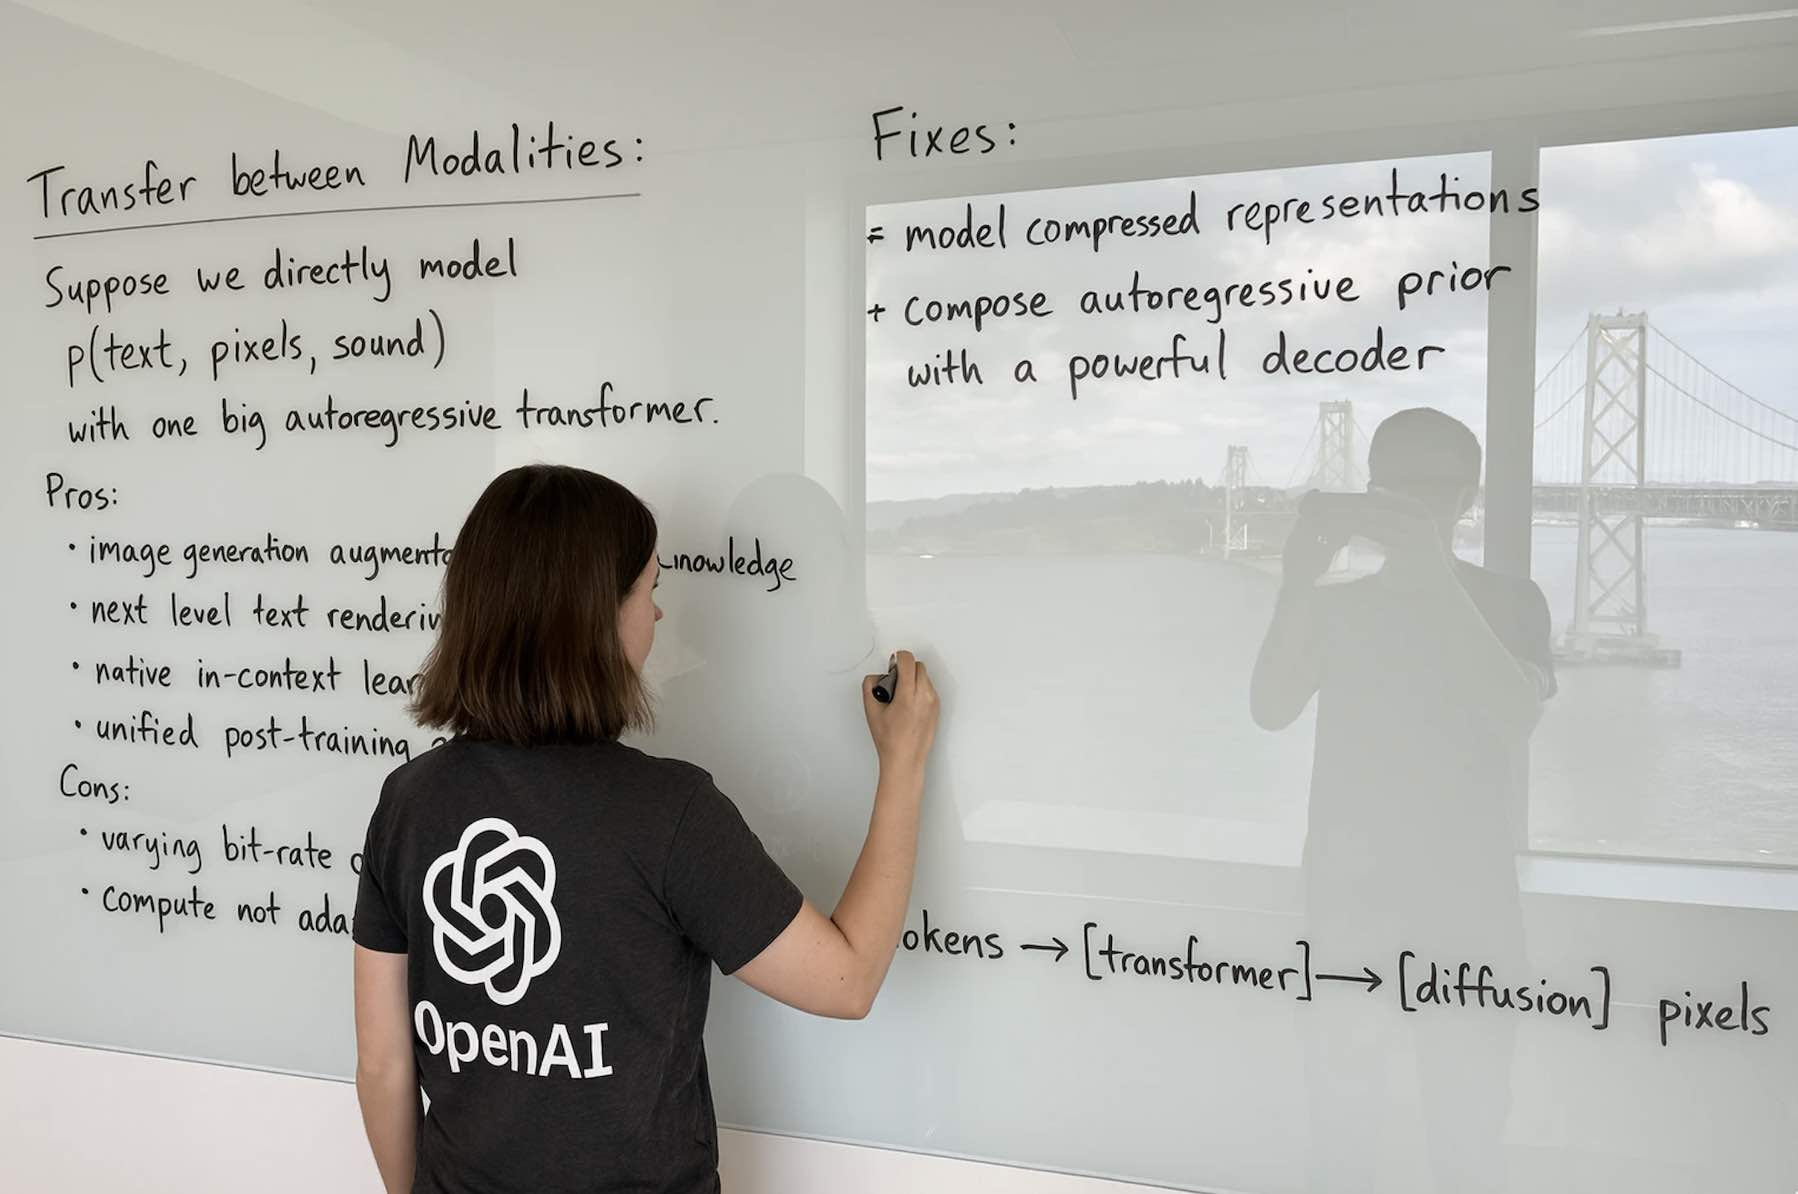

In [34]:
from IPython.display import Image, display                  # show the image in the notebook

display(Image("../images/imagetotext1.jpg", width=600))     # the photo we will ask about

In [35]:
import base64                                               # encode the image's bytes as text
from langchain.chat_models import init_chat_model           # Way 3, as in the rest of the notebook
from langchain.messages import HumanMessage                 # a message written by the user

with open("../images/imagetotext1.jpg", "rb") as f:         # "rb": read the raw bytes of the file
    image_base64 = base64.b64encode(f.read()).decode()      # bytes → base64 text

message = HumanMessage(content=[                            # one message, two blocks
    {"type": "text", "text": "Describe this image in three sentences."},
    {"type": "image", "base64": image_base64, "mime_type": "image/jpeg"},
])

gemini_vision = init_chat_model(
    "google_genai:gemini-3.5-flash-lite",                   # reads images (free tier)
    max_tokens=400,                                         # maximum length of the reply
)
qwen_vision = init_chat_model(
    "groq:qwen/qwen3.8-27b",                                # reads images too (free tier)
    max_tokens=400,                                         # maximum length of the reply
)
vision_models = {
    "Google · gemini-3.5-flash-lite": gemini_vision,
    "Groq   · qwen/qwen3.8-27b": qwen_vision,
}

for name, model in vision_models.items():                   # a check without any call
    if model.profile is None:
        image_inputs = "unknown (LangChain has no profile for this model)"
    else:
        image_inputs = model.profile.get("image_inputs")
    print(f"{name:32} image_inputs = {image_inputs}")
print()

for name, model in vision_models.items():                   # the same message to both
    reply = model.invoke([message])
    print(f"\033[1m=== {name} ===\033[0m")
    print(reply.text.strip(), "\n")

Google · gemini-3.5-flash-lite   image_inputs = True
Groq   · qwen/qwen3.8-27b        image_inputs = unknown (LangChain has no profile for this model)

=== Google · gemini-3.5-flash-lite ===
A woman wearing an OpenAI t-shirt is writing on a glass whiteboard with a black marker in her right hand. The whiteboard has handwritten notes titled "Transfer between Modalities:" on the left side and "Fixes:" on the right side. The whiteboard reflects a view of a bridge and a person holding a phone or camera. 

=== Groq   · qwen/qwen3.8-27b ===
A person wearing a black OpenAI t-shirt is writing on a whiteboard next to a large window with a view of a bridge. The whiteboard contains handwritten notes about "Transfer between Modalities" and "Fixes," discussing concepts like modeling p(text, pixels, sound) with an autoregressive transformer. The text outlines pros such as "image generation augmentation" and cons like "varying bit-rate," along with a diagram showing tokens flowing through a transforme

## <span style='color:#7e22ce'>Example 11: Image out: OpenAI's image tool, and a local model</span>
### Step 1: With LangChain and OpenAI's `image_generation` tool (paid)
- OpenAI's `image_generation` is a **hosted tool**: we create `gpt-4o-mini` with `init_chat_model()` (a `ChatOpenAI` behind it), give it the tool with `bind_tools()`, the model decides to draw, and OpenAI's image model (`gpt-image-1-mini`, low quality: the cheapest setting) does the drawing.
- The picture comes back as a standard **`image` content block**, with base64 data. (We meet tools properly in Lec-40.)

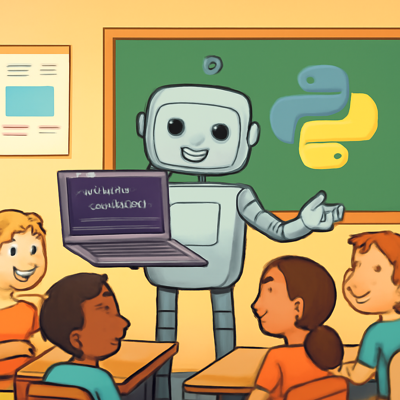

In [36]:
import io                                                   # io.BytesIO: treat bytes in memory like a file
import base64                                               # decode the picture from base64 text
from PIL import Image as PILImage                           # open and resize the picture (named to avoid IPython's Image)
from IPython.display import display                         # show the picture in the notebook
from langchain.chat_models import init_chat_model           # Way 3, as in the rest of the notebook

image_tool = {"type": "image_generation", "model": "gpt-image-1-mini", "quality": "low", "size": "1024x1024"}
painter = init_chat_model("openai:gpt-4o-mini").bind_tools([image_tool])   # a ChatOpenAI, so OpenAI's own tools work; it may now draw

reply = painter.invoke("Draw a simple, friendly cartoon of a robot teaching Python to students in a classroom.")
for block in reply.content_blocks:                          # the reply holds an image block (and maybe some text)
    if block["type"] == "image":
        picture = PILImage.open(io.BytesIO(base64.b64decode(block["base64"])))   # base64 → bytes → picture
        display(picture.resize((400, 400)))                 # a smaller copy in the notebook

### Step 2: A free model on your laptop, without LangChain
- `stabilityai/sd-turbo` is a small open text-to-image model that runs on a CPU through Hugging Face's `diffusers` library (not LangChain). The first run downloads it.
- **SD-Turbo** was trained to draw in **1 to 4 steps** with **no guidance** (`guidance_scale=0.0`): more steps or a higher guidance scale make its pictures worse, not better.

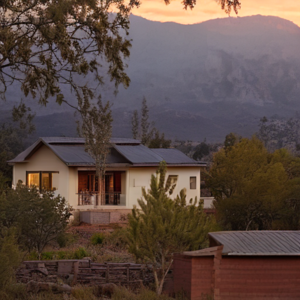

In [37]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"            # no download progress bars in the saved output
import warnings                                             # hide library warnings we expect
warnings.filterwarnings("ignore")
import torch                                                # PyTorch, which runs the model
from transformers.utils import logging as transformers_logging   # transformers' own messages (diffusers uses it)
transformers_logging.set_verbosity_error()                  # print only errors
from diffusers import AutoPipelineForText2Image             # Hugging Face's text-to-image pipelines
from diffusers.utils import logging as diffusers_logging    # diffusers' own messages
from IPython.display import display                         # show the picture in the notebook

diffusers_logging.set_verbosity_error()                     # print only errors
diffusers_logging.disable_progress_bar()                    # and no progress bars

pipe = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", dtype=torch.float32).to("cpu")   # float32 for CPU
pipe.set_progress_bar_config(disable=True)                  # no progress bar while it draws

image = pipe(prompt="A house at sunset, with trees and mountains in the background",
             num_inference_steps=1,                         # SD-Turbo: 1 to 4 steps
             guidance_scale=0.0).images[0]                  # SD-Turbo: no classifier-free guidance
display(image.resize((300, 300)))

# <span style='background :lightgreen' >7. Audio In and Out</span>

- In Lec-14 we worked with audio through separate tools: `whisper-1` and `whisper-base` for speech → text, and `tts-1`, gTTS and Bark for text → speech. Each one has its own API or library, and none of them is a chat model.
- **In LangChain, audio goes through a chat model**, exactly like images in Section 6 (see the figure there): audio **in** is an `audio` content block in a `HumanMessage`, and audio **out** comes back as an `audio` content block in the `AIMessage`.
- Only some models can do this, and `profile["audio_inputs"]` tells us which ones can read audio. We use Google's Gemini models.
- **Note:** a text-to-speech model that runs on your laptop, such as Bark through Hugging Face's `transformers` pipeline (Lec-14), is **not** LangChain: LangChain has no class for local speech models, so for those we keep using `transformers` directly.

## <span style='color:#7e22ce'>Example 12: Audio in: transcribe and translate a speech clip</span>
We send the Urdu clip of Lec-14 as an `audio` block (base64 text, with its type), together with a `text` block that says what to do.

In [38]:
from IPython.display import Audio, display                  # play audio inside the notebook

display(Audio("../data/audios/arif-urdu-audio.mp3"))        # the clip we will send to the model

In [39]:
import base64                                               # encode the audio's bytes as text
from langchain.chat_models import init_chat_model           # Way 3, as in the rest of the notebook
from langchain.messages import HumanMessage                 # a message written by the user

with open("../data/audios/arif-urdu-audio.mp3", "rb") as f: # "rb": read the raw bytes of the file
    audio_base64 = base64.b64encode(f.read()).decode()      # bytes → base64 text

listener = init_chat_model(
    "google_genai:gemini-3.5-flash-lite",                   # a chat model that can read audio (free tier)
)
print("Can it read audio?", listener.profile["audio_inputs"])   # from the model's profile, without any call
print()

tasks = [
    "Transcribe this audio exactly, in Urdu script.",       # speech → text, in the same language
    "Translate this audio into English.",                   # speech → text, in another language
]
for task in tasks:
    message = HumanMessage(content=[                        # one message, two blocks: what to do, and the audio
        {"type": "text", "text": task},
        {"type": "audio", "base64": audio_base64, "mime_type": "audio/mpeg"},   # an mp3 file is "audio/mpeg"
    ])
    reply = listener.invoke([message])
    print(f"\033[1m{task}\033[0m")
    print(reply.text, "\n")

Can it read audio? True

Transcribe this audio exactly, in Urdu script.
عزیز طلبہ، السلام علیکم! میں آپ سب کو جنریٹیو آرٹیفیشل انٹیلیجنس کے کورس میں خوش آمدید کہتا ہوں۔ 

Translate this audio into English.
Dear students, Assalam-o-Alaikum! I welcome you all to the Generative Artificial Intelligence course. 



## <span style='color:#7e22ce'>Example 13: Audio out: text to speech, and back again</span>
- `response_modalities=["AUDIO"]` asks a Gemini text-to-speech model to answer with **sound** instead of text. The answer is an `audio` content block: a WAV file, as base64 text.
- Then we close the loop: we send the generated audio back to the `listener` of Example 13 and ask for a transcript (the cross-modal chain of Lec-14, now in LangChain).
- OpenAI's `gpt-audio-mini` can also speak through `ChatOpenAI`, but it is paid, and it returns the audio in `additional_kwargs` instead of a standard content block.

In [40]:
import base64                                               # decode the audio from base64 text
from IPython.display import Audio, display                  # play audio inside the notebook
from langchain.chat_models import init_chat_model           # Way 3, as in the rest of the notebook
from langchain.messages import HumanMessage                 # a message written by the user

speaker = init_chat_model(
    "google_genai:gemini-3.8-flash-lite-tts",               # Google's text-to-speech model
    response_modalities=["AUDIO"],                          # answer with sound, not text
)
reply = speaker.invoke("Dear students, welcome to the course on Generative Artificial Intelligence.")

for block in reply.content_blocks:                          # the reply holds one audio block
    if block["type"] == "audio":
        speech_base64 = block["base64"]                     # the WAV file, as base64 text
        print("mime_type:", block["mime_type"])             # audio/wav
        wav_bytes = base64.b64decode(speech_base64)         # base64 text → bytes
        display(Audio(data=wav_bytes))                      # play it

# ... and back again: audio → text, with the listener of Example 13
message = HumanMessage(content=[
    {"type": "text", "text": "Transcribe this audio exactly."},
    {"type": "audio", "base64": speech_base64, "mime_type": "audio/wav"},
])
transcript = listener.invoke([message])
print("Transcript:", transcript.text)

mime_type: audio/wav


Transcript: Dear students, welcome to the course on Generative Artificial Intelligence.


# <span style='background :lightgreen' >8. Hands-On Practice: a Final Exercise</span>

To finish, we use what we learned on everyday tasks. A small helper, `ask()`, keeps the practice examples short. It works with any LangChain chat model: by default Groq's `gpt-oss-120b` (the `default_model` of Section 4), or `"openrouter"` for a free OpenRouter model with a backup (Example 4).

In [41]:
from langchain.chat_models import init_chat_model           # Way 3, as in the rest of the notebook
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's message

openrouter_free = init_chat_model(
    "openrouter:nvidia/nemotron-3-ultra-550b-a55b:free",    # a free model ...
    max_tokens=2000,                                        # a reasoning model: needs room to think
    model_kwargs={
        "models": ["nvidia/nemotron-3.5-super-vl:free"],    # ... with one backup (Example 4)
    },
)
CHAT_MODELS = {
    "groq": default_model,                                  # Groq's gpt-oss-120b, from Section 4
    "openrouter": openrouter_free,
}

def ask(user_prompt, system_prompt="You are a helpful assistant that provides concise answers.",
        model="groq", temperature=None, stream=False):
    '''Send one question to a chat model; return the answer's text (or a stream of chunks).'''
    chat_model = CHAT_MODELS[model]
    if temperature is not None:
        chat_model = chat_model.bind(temperature=temperature)   # .bind(): the same model with one setting changed
    messages = [SystemMessage(system_prompt), HumanMessage(user_prompt)]   # the same messages for every provider
    if stream:
        return chat_model.stream(messages)                  # the caller loops over the chunks
    return chat_model.invoke(messages).text                 # only the text of the answer

## a. Question answering

In [42]:
print(ask("Which is the capital of Pakistan?"))

Islamabad.


In [43]:
print(ask("Who is Imran Khan? Answer in three sentences.", model="openrouter"))   # the same helper, a free OpenRouter model

Imran Khan is a former Pakistani cricketer who captained the national team to its first Cricket World Cup victory in 1992. He entered politics in 1996, founding the Pakistan Tehreek-e-Insaf (PTI) party, and served as Prime Minister from 2018 until his removal by a no‑confidence vote in 2022. Since leaving office, he remains a prominent opposition leader and continues to shape Pakistani politics.


## b. Question answering from the content we pass

In [44]:
with open("../data/names.txt", "r") as f:                   # a text file with a few names
    file_content = f.read()

print(ask(f"Extract the names of the cricket players from this text:\n{file_content}"))

Imran Khan  
Wasim Akram  
Shahid Afridi  
Babar Azam  
Shaheen Shah Afridi  
Shadab Khan


## c. Binary classification (sentiment analysis, spam detection, …)

In [45]:
system_prompt = "Classify the sentiment of the sentence as either Positive or Negative. Reply with one word."
print(ask("I love the YouTube videos of Arif, as they are very informative.", system_prompt))

Positive


## d. Multi-class classification

In [46]:
system_prompt = ("Classify product reviews into these categories: 'Electronics', 'Clothing', 'Books', "
                 "'Home & Garden', 'Sports', or 'Food'. Respond with only the category.")
print(ask("This novel has an incredible plot twist that kept me reading all night.", system_prompt))

Books


## e. Classifying many reviews at once with `batch()`
The same instructions for five reviews, sent together with `batch()` (Section 3).

In [47]:
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's message

reviews = ["The running shoes fell apart after one week of jogging.",
           "Fresh mangoes, very sweet, delivered on time.",
           "The earphones stopped charging after a month.",
           "This cotton shirt shrank after the first wash.",
           "A great introduction to machine learning; the examples are clear."]

conversations = [[SystemMessage(system_prompt), HumanMessage(review)] for review in reviews]   # one list of messages each
for review, reply in zip(reviews, default_model.batch(conversations)):   # system_prompt is the one of section d
    print(f"{reply.text:12} ← {review}")

Sports       ← The running shoes fell apart after one week of jogging.
Food         ← Fresh mangoes, very sweet, delivered on time.
Electronics  ← The earphones stopped charging after a month.
Clothing     ← This cotton shirt shrank after the first wash.
Books        ← A great introduction to machine learning; the examples are clear.


## f. Text generation

In [48]:
system_prompt = "You are an expert in political science and history, with a deep understanding of Pakistan's politics."
print(ask("Write a 50-word summary about the fairness of the general elections held in Pakistan on February 8, 2024.",
          system_prompt, temperature=1.5))                  # a high temperature: more varied wording

Since the February 8 2024 Pakistani general election has not occurred, objective assessments of its fairness remain unavailable. No official results, observer reports, or credible analyses have been published, preventing any definitive evaluation of transparency, voter access, or alleged irregularities. Future monitoring missions may later provide insight into procedural integrity and confidence.


## g. Code generation (streamed)

In [49]:
for chunk in ask("Write a C program that prints the first ten numbers of the Fibonacci sequence.",
                 "You are an expert C programmer.", stream=True):
    print(chunk.text, end="", flush=True)                   # print each piece as it arrives

**C program – first 10 Fibonacci numbers**

```c
/*  fibonacci.c
 *
 *  Prints the first ten numbers of the Fibonacci sequence:
 *  0 1 1 2 3 5 8 13 21 34
 *
 *  Compile with:  gcc -Wall -Wextra -O2 fibonacci.c -o fibonacci
 *  Run:           ./fibonacci
 */

#include <stdio.h>

int main(void)
{
    const int N = 10;          /* how many numbers to print */
    long long f0 = 0, f1 = 1;  /* first two Fibonacci numbers */
    long long next;
    int i;

    /* Print the first number (0) */
    printf("%lld", f0);

    /* Print the remaining N‑1 numbers */
    for (i = 1; i < N; ++i) {
        /* The current number to output is f1 for i==1, then the
         * newly computed value for later iterations. */
        printf(" %lld", f1);

        /* Compute the next Fibonacci number */
        next = f0 + f1;
        f0   = f1;
        f1   = next;
    }

    putchar('\n');
    return 0;
}
```

### How it works
1. `f0` and `f1` hold the two most recent Fibonacci numbers.  
2. The first value

## h. Translation

In [50]:
system_prompt = "You are an expert English-to-Urdu translator. Translate the user's text into Urdu."
print(ask("The budget this year will have a very bad impact on low-salaried people.", system_prompt))

اس سال کا بجٹ کم آمدنی والے افراد پر بہت منفی اثر ڈالے گا۔


## i. Summarisation

In [51]:
bio_text = '''
Dr. Muhammad Arif Butt is an accomplished Assistant Professor at the Department of Data Science, University of the Punjab (PU), Lahore, Pakistan.
He holds an MSc and MPhil (both with Gold Medals) and a Ph.D. in Computer Science from PUCIT, University of the Punjab. His research focuses on fuzzy
inference models applied to operating systems, embedded systems, and cloud-based services, particularly in decision-making under uncertain and
imprecise conditions. With over 33 years of experience in teaching and management, Dr. Butt has served in both the Pakistan Army and University
of the Punjab, bringing a wealth of interdisciplinary expertise. His teaching specializations include embedded and real-time operating systems, system programming,
cybersecurity, and artificial intelligence. Beyond academia, he is a technology entrepreneur, serving as the Founder of Excaliat and Falcon-Hunt and Co-Founder of Tbox Solutionz.
In recent years, he has gained significant expertise in vulnerability research, binary exploitation, and exploit development, excelling in identifying and mitigating critical security risks
across diverse platforms. His deep understanding of software architectures, memory corruption techniques, and attack vectors strengthens his ability to proactively enhance cybersecurity defences.
A dedicated and results-driven professional, Dr. Butt is recognized for his strong organizational skills, strategic thinking, and ability to thrive in collaborative environments.
His expertise in cybersecurity and emerging technologies enables him to contribute effectively to both academic research and industry innovation, reinforcing defences against evolving cyber threats.
'''

print(ask(f"Summarize the text below in at most 50 words:\n\n{bio_text}", "You are an expert of the English language.",
          model="openrouter"))                              # a free OpenRouter model

Dr. Muhammad Arif Butt is an Assistant Professor of Data Science at the University of the Punjab, Lahore, with a Ph.D. in Computer Science and 33+ years of military and academic experience. A gold medalist, he researches fuzzy inference for decision-making in OS and cloud systems. He teaches embedded systems, cybersecurity, and AI, while founding tech ventures Excaliat, Falcon-Hunt, and Tbox Solutionz. His expertise spans vulnerability research, binary exploitation, and proactive defense against cyber threats.


## j. Named entity recognition

In [52]:
system_prompt = '''You are a named entity recognition specialist. Extract and classify the entities of the text into these
categories, only if they exist: name, major, university, nationality, grades, club.
Format each entity on its own line as: Entity: [text] | Type: [category]'''

user_prompt = '''Zelaid Mujahid is a sophomore majoring in Data Science at the University of the Punjab.
He is a Pakistani national and has a 3.5 GPA. Mujahid is an active member of the department's AI Club.
He hopes to pursue a career in AI after graduating.'''

print(ask(user_prompt, system_prompt))

Entity: Zelaid Mujahid | Type: name  
Entity: Data Science | Type: major  
Entity: University of the Punjab | Type: university  
Entity: Pakistani | Type: nationality  
Entity: 3.5 GPA | Type: grades  
Entity: AI Club | Type: club


# <span style='background :lightgreen' >9. The Road Ahead</span>

<div style="text-align:center;">
    <img src="../images/langchain-new-03.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

> **Documentation:** https://docs.langchain.com/oss/python/langchain/overview · Models: https://docs.langchain.com/oss/python/langchain/models